# Lab 1 — MountainCar: Policy Iteration vs Value Iteration

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mountain_car_setup import *

N_POS, N_VEL = 200, 200
GAMMA, THETA, EPSILON = 0.99, 1e-4, 1e-4

## 1. Discretization

- The state (position, velocity) is continuous, but PI/VI need a finite table of states.
- We split position into `N_POS` bins and velocity into `N_VEL` bins → each cell is one state (200×200 = 40 000 states).

In [2]:
i, j = discretize([-0.5, 0.0], N_POS, N_VEL)
print("discretize(-0.5, 0.0) ->", (i, j))
print("undiscretize ->", undiscretize(i, j, N_POS, N_VEL), "(centre of that bin)")

discretize(-0.5, 0.0) -> (77, 100)
undiscretize -> (-0.5025, 0.0003500000000000031) (centre of that bin)


## 2. Model: tables P and R

- For every (state, action): put the car at the bin centre, do one `step`, record where it lands (one step per pair is enough, because the physics is deterministic)
- `P[s, a]` = next state, `R[s, a]` = reward (always -1), `done[s, a]` = this step reaches the flag.

In [3]:
t = time.perf_counter()
P, R, done = build_model(N_POS, N_VEL)
build_time = time.perf_counter() - t
print(f"P, R, done shape: {P.shape}")
print(f"model built in {build_time:.2f} s")

P, R, done shape: (40000, 3)
model built in 1.13 s


## 3. Policy Iteration and Value Iteration

- **PI**: start with "do nothing" everywhere → evaluate the policy until V settles → switch each state to its best action → repeat until the policy stops changing.
- **VI**: no policy during the loop → each sweep sets `V(s) = max over actions [R + γ·V(s')]` → extract the policy once at the end.

In [4]:
pi = policy_iteration(P, R, done, GAMMA, THETA)
vi = value_iteration(P, R, done, GAMMA, EPSILON)
print(f"PI: {pi['iterations']} outer iterations, {pi['eval_sweeps']} evaluation sweeps, {pi['time']:.2f} s")
print(f"VI: {vi['iterations']} sweeps, {vi['time']:.2f} s")
print("same V:", np.allclose(pi["V"], vi["V"]), "| same policy:", np.array_equal(pi["policy"], vi["policy"]))

PI: 93 outer iterations, 4326 evaluation sweeps, 0.76 s
VI: 110 sweeps, 0.11 s
same V: True | same policy: True


- Both methods reach the same V and the same policy
- PI has fewer outer iterations, but each one is a full evaluation of many sweeps
- VI needs only ~110 sweeps: the `max` improves the values on every sweep, so it never spends time measuring a bad policy exactly.

## 4. Testing and comparison (100 episodes in the real continuous environment)

In [5]:
test_pi = test_policy(pi["policy"], N_POS, N_VEL)
test_vi = test_policy(vi["policy"], N_POS, N_VEL)

pd.DataFrame({
    "Policy Iteration": [build_time, pi["iterations"], pi["eval_sweeps"], pi["time"],
                         test_pi["mean_steps"], test_pi["success_%"], test_pi["mean_reward"]],
    "Value Iteration":  [build_time, vi["iterations"], vi["iterations"], vi["time"],
                         test_vi["mean_steps"], test_vi["success_%"], test_vi["mean_reward"]],
}, index=["Model build time, s (shared)", "Outer iterations", "Total sweeps", "Training time, s",
          "Mean steps to flag", "Success rate, %", "Mean total reward"]).round(2)

,Policy Iteration,Value Iteration
"Model build time, s (shared)",1.13,1.13
Outer iterations,93.00,110.00
Total sweeps,4326.00,110.00
"Training time, s",0.76,0.11
Mean steps to flag,120.41,120.41
"Success rate, %",100.00,100.00
Mean total reward,-120.41,-120.41


**Conclusion**

- Both policies reach the flag in 100% of test episodes with the same number of steps, because they are the same policy.
- **VI is faster**: several times less training time and ~40× fewer sweeps.
- Mean reward = −(mean steps), because every step gives −1.

## 5. Visualization

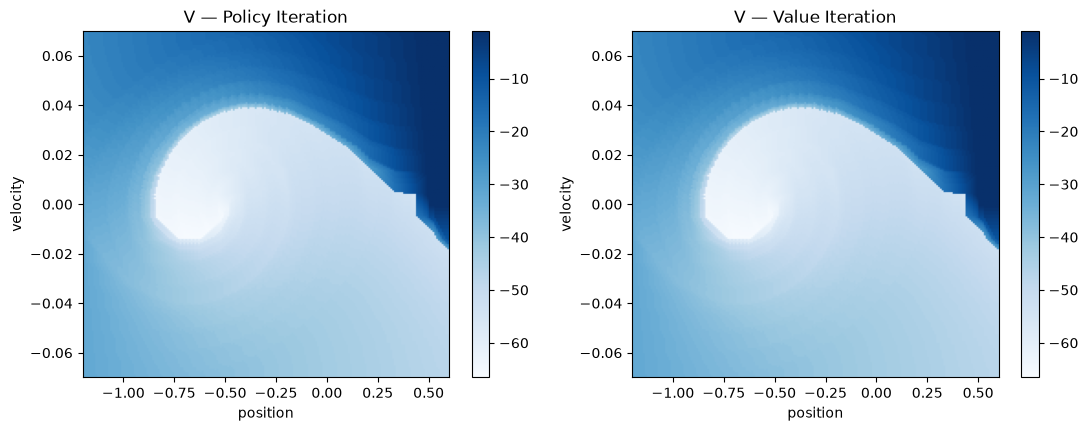

In [6]:
extent = [POS_MIN, POS_MAX, VEL_MIN, VEL_MAX]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (name, res) in zip(axes, [("Policy Iteration", pi), ("Value Iteration", vi)]):
    im = ax.imshow(res["V"].reshape(N_POS, N_VEL).T, origin="lower", aspect="auto", extent=extent, cmap="Blues")
    ax.set(title=f"V — {name}", xlabel="position", ylabel="velocity")
    fig.colorbar(im, ax=ax)
plt.show()

- Identical maps, as expected: both methods converge to the same optimal V.
- Dark (close to 0) = few steps to the flag: on the right, or moving fast to the right.
- Light spiral in the middle = the car is near the bottom with low speed → it must swing back and forth to build momentum, so many steps remain.

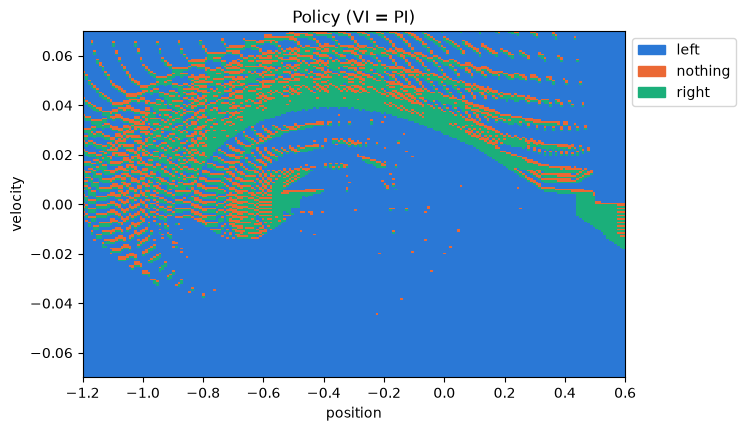

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

colors = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.imshow(vi["policy"].reshape(N_POS, N_VEL).T, origin="lower", aspect="auto", extent=extent,
          cmap=ListedColormap(colors), interpolation="nearest")
ax.set(title="Policy (VI = PI)", xlabel="position", ylabel="velocity")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, ["left", "nothing", "right"])],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- The main rule: **push in the direction you are already moving** → this is how the car swings up.
- The green band (push right) follows the spiral of V: these are the states where pushing right leads up the hill.
- Large blue areas are mostly ties: V depends only on the number of steps to the flag, and there several actions reach the flag in the same number of steps → `argmax` picks the first one, "left".

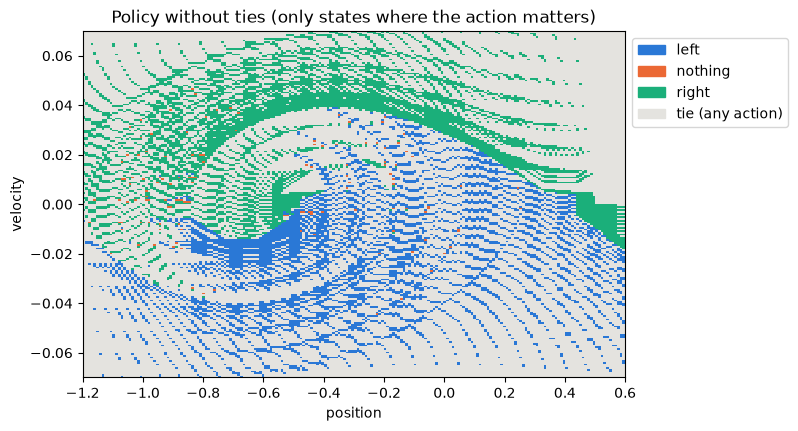

ties: 71% of states


In [ ]:
Q = q_values(vi["V"], P, R, done, GAMMA)
ties = (np.isclose(Q, Q.max(axis=1, keepdims=True)).sum(axis=1) > 1)  # several actions equally best
true_policy = np.where(ties, 3, vi["policy"])                          # 3 = "tie" (shown grey)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.imshow(true_policy.reshape(N_POS, N_VEL).T, origin="lower", aspect="auto", extent=extent,
          cmap=ListedColormap(colors + ["#e4e3df"]), vmin=0, vmax=3, interpolation="nearest")
ax.set(title="Policy without ties (only states where the action matters)", xlabel="position", ylabel="velocity")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors + ["#e4e3df"], ["left", "nothing", "right", "tie (any action)"])],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()
print(f"ties: {ties.mean() * 100:.0f}% of states")

- Grey = ties: all best actions reach the flag in the same number of steps, so the choice doesn't matter.
- What's left is the real strategy: **right** when moving right (green, the upper part), **left** when moving left (blue, the lower part) → push in the direction of motion to pump the swing.

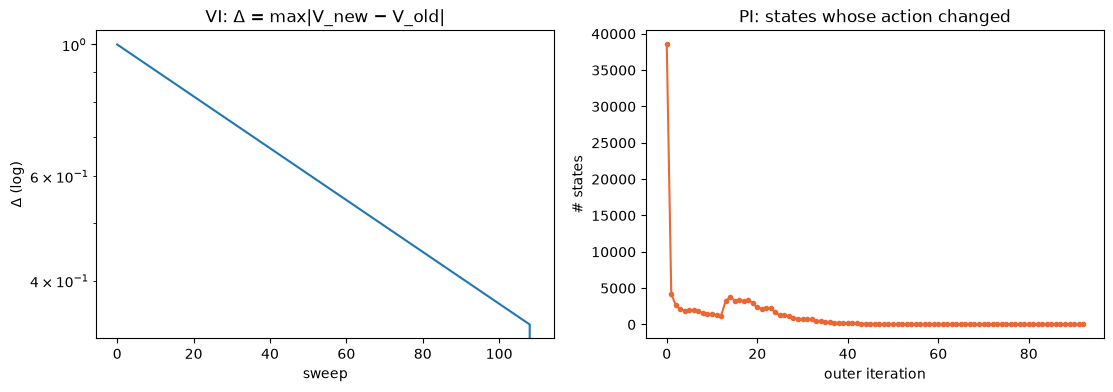

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].semilogy(vi["deltas"])
axes[0].set(title="VI: Δ = max|V_new − V_old|", xlabel="sweep", ylabel="Δ (log)")
axes[1].plot(pi["changes"], marker="o", ms=3, color="#eb6834")
axes[1].set(title="PI: states whose action changed", xlabel="outer iteration", ylabel="# states")
plt.show()

- **VI**: Δ shrinks by ×γ every sweep (the values far from the flag keep sinking), then drops to 0 once the flag signal has reached every state.
- **PI**: thousands of states change their action in the first iterations, then fewer and fewer → the "good zone" grows outward from the flag, one ring per outer iteration.

## 6. Simulation

steps: 106, reached flag: True


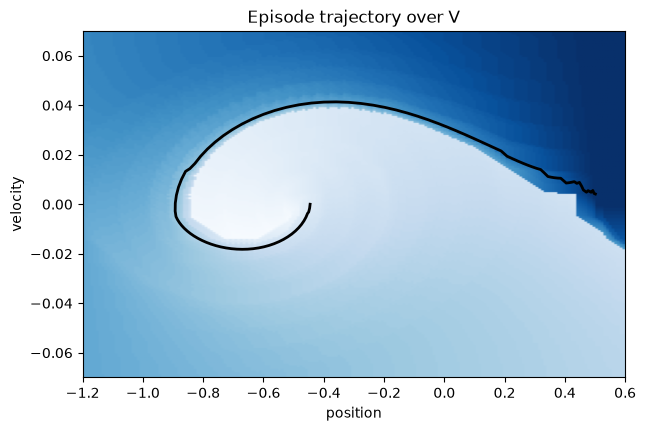

In [9]:
total_reward, reached, traj, frames = run_episode(vi["policy"], N_POS, N_VEL, seed=42, render_mode="rgb_array")
print(f"steps: {len(traj) - 1}, reached flag: {reached}")

plt.figure(figsize=(7, 4.5))
plt.imshow(vi["V"].reshape(N_POS, N_VEL).T, origin="lower", aspect="auto", extent=extent, cmap="Blues")
plt.plot(traj[:, 0], traj[:, 1], color="black", lw=2)
plt.title("Episode trajectory over V")
plt.xlabel("position"); plt.ylabel("velocity")
plt.show()

- The trajectory spirals outward: the car first goes left (negative velocity), then swings right with more speed.
- It always moves toward darker (better) states, so it follows V up to the flag.

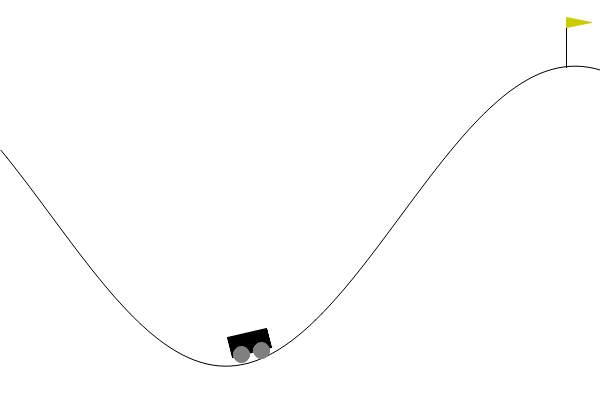

In [10]:
from PIL import Image as PILImage
from IPython.display import Image

gif = [PILImage.fromarray(f) for f in frames[::2]]
gif[0].save("episode.gif", save_all=True, append_images=gif[1:], duration=40, loop=0)
Image(filename="episode.gif")

## 7. Experiment: grid size

- Does the recommended 40×40 grid work? Run VI on several grid sizes and test each policy.

In [11]:
rows = []
for n in [40, 60, 100, 150, 200]:
    P_n, R_n, done_n = build_model(n, n)
    res = value_iteration(P_n, R_n, done_n, GAMMA, EPSILON)
    rows.append({"grid": f"{n}x{n}", "VI sweeps": res["iterations"],
                 "success %": test_policy(res["policy"], n, n)["success_%"]})
grid_df = pd.DataFrame(rows).set_index("grid")
grid_df

,VI sweeps,success %
grid,,
40x40,918,0.0
60x60,918,0.0
100x100,113,42.0
150x150,110,93.0
200x200,110,100.0


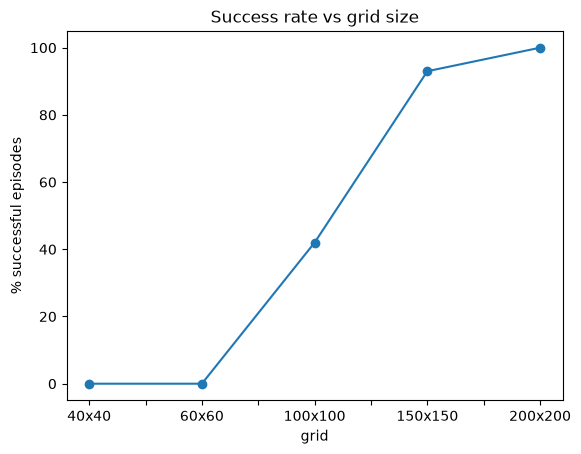

In [12]:
grid_df["success %"].plot(marker="o", ylim=(-5, 105), title="Success rate vs grid size", ylabel="% successful episodes")
plt.show()

- **Coarse grids fail completely** (0% at 40×40 and 60×60).
- Reason: the model is one step from the **bin centre**. On a coarse grid one step moves the car less than half a bin → it lands back in the same bin → the model thinks the car cannot move (especially near the start, where speed is ~0).
- So for those states the flag looks unreachable, all actions look equally bad, and the policy is useless.
- Finer grid → steps cross bin borders → the model matches reality → 100% success at 200×200.
- On coarse grids VI also needs more sweeps (918): states that "can't reach" the flag sink slowly toward −1/(1−γ) = −100.